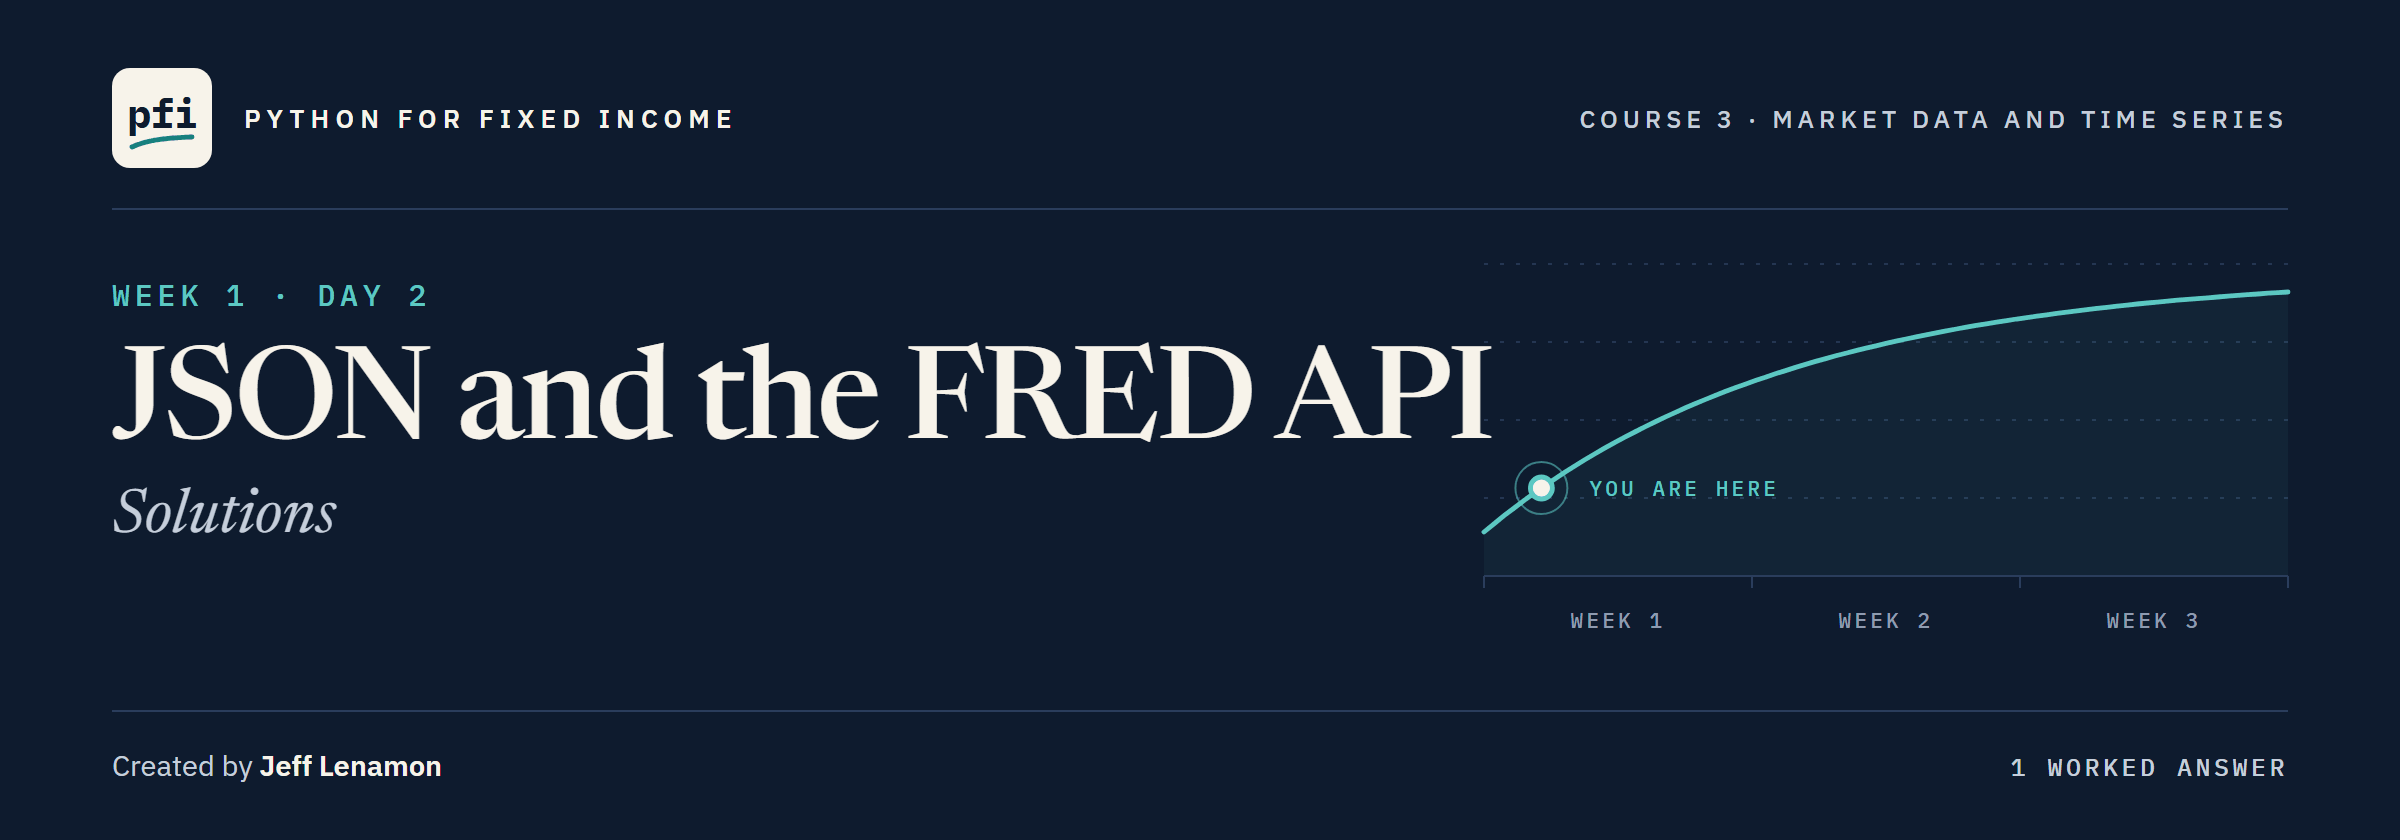

# JSON and the FRED API: Solutions

Week 1, Day 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day2/02_json_and_the_fred_api_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports, `check`, and the two samples.

No key is needed.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 02 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(2, after=2)

Work folder pfi_course3_02_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 02 left it, 2 commits


In [2]:
import importlib
import json
from pathlib import Path

import pandas as pd

import marketdata as md

print('parse_fred_observations is in the module:', 'parse_fred_observations' in dir(md))

parse_fred_observations is in the module: True


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
# the two samples as dicts: the 10-year and the 2-year
sample10 = json.loads(Path('course3_fred_format_dgs10.json').read_text(encoding='utf-8'))
sample2 = json.loads(Path('course3_fred_format_dgs2.json').read_text(encoding='utf-8'))
print(sample10['count'], 'and', sample2['count'], 'observations')

43 and 43 observations


### Exercise 1

In [5]:
dgs2 = md.parse_fred_observations(sample2, 'DGS2')
ex1_value = dgs2.loc['2026-09-30']
print(len(dgs2), 'rows,', dgs2.isna().sum(), 'NaN; 2026-09-30:', ex1_value, 'percent')

43 rows, 1 NaN; 2026-09-30: 4.88 percent


In [6]:
check('Exercise 1 the 2-year on 2026-09-30', ex1_value, 4.88)

Exercise 1 the 2-year on 2026-09-30: correct


The same function reads any series in FRED's layout: only the name changes.
The 2-year's dot falls on Labor Day too.

### Exercise 2

In [7]:
# keep the date of each observation whose value is the dot
dot_dates = [obs['date'] for obs in sample10['observations'] if obs['value'] == '.']
ex2_dots = len(dot_dates)
ex2_date = dot_dates[0]
print(dot_dates)

['2026-09-07']


In [8]:
check('Exercise 2 the number of dots', ex2_dots, 1)
check('Exercise 2 the date of the dot', ex2_date, '2026-09-07')

Exercise 2 the number of dots: correct
Exercise 2 the date of the dot: correct


A dot is text, so `==` against `'.'` finds it before anything is converted.

### Exercise 3

In [9]:
%%writefile -a marketdata.py


def observation_count(payload: dict) -> dict:
    """Count the observations of a FRED series/observations answer: all of them, the numbers, the dots.

    Units: counts. Convention: "." is FRED's missing marker, so it counts as missing, never as a number,
    and the answer's own count must equal the length of its list.
    Raises ValueError if the answer has no "observations" list, or if its count disagrees with the list.
    """
    if "observations" not in payload:
        raise ValueError(f"the answer has no 'observations'; keys are {sorted(payload)}")
    values = [obs["value"] for obs in payload["observations"]]
    if payload.get("count") != len(values):
        raise ValueError(f"count says {payload.get('count')}, the list holds {len(values)}")
    missing = len([value for value in values if value == "."])
    return {"total": len(values), "numeric": len(values) - missing, "missing": missing}

Appending to marketdata.py


In [10]:
%%writefile -a test_marketdata.py


def test_observation_count_sample():
    sample = read_sample("DGS2")
    assert md.observation_count(sample) == {"total": 43, "numeric": 42, "missing": 1}
    # a count that disagrees with the list stops the function
    with pytest.raises(ValueError):
        md.observation_count(sample | {"count": 99})

Appending to test_marketdata.py


In [11]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........                                                               [100%]
10 passed in 0.50s



In [12]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_counts = md.observation_count(sample2)
print(ex3_counts)

{'total': 43, 'numeric': 42, 'missing': 1}


In [13]:
check('Exercise 3 the counts', ex3_counts, {'total': 43, 'numeric': 42, 'missing': 1})

Exercise 3 the counts: correct


`count` is FRED's own figure: checking it against the list catches an answer cut short on its way to you.

### Exercise 4: AI check

The bug: the comment's reason, "so the column stays numeric", is the trap of 2.4.
A 0 on Labor Day makes a 480 bp move that never happened and drags every average and window down.
The fix keeps the dot as `NaN`, as `parse_fred_observations` does.

In [14]:
# written for this course in the style of an AI assistant's answer, now fixed
def parse_yields(payload, name):
    """Turn a FRED series/observations answer into a float series indexed by date.

    Units: percent, as FRED publishes. Convention: FRED's missing marker "." becomes NaN and is
    kept, so a day with no yield never looks like a yield of 0.
    """
    dates = pd.to_datetime([obs['date'] for obs in payload['observations']])
    # the fix: "." becomes NaN, never 0.0
    values = [float('nan') if obs['value'] == '.' else float(obs['value'])
              for obs in payload['observations']]
    return pd.Series(values, index=dates, name=name)

In [15]:
# the test, written from the docstring before the code is trusted
result = parse_yields(sample10, 'DGS10')
assert (result == 0).sum() == 0, 'a yield of 0 percent'
assert result.isna().sum() == 1, 'the dot did not become NaN'
print('No yield is 0, and the dot is NaN')

No yield is 0, and the dot is NaN


In [16]:
ex4_holiday_is_nan = bool(result.isna().loc['2026-09-07'])
ex4_zero_count = int((result == 0).sum())
check('Exercise 4 Labor Day is NaN', ex4_holiday_is_nan, True)
check('Exercise 4 no yield is 0', ex4_zero_count, 0)

Exercise 4 Labor Day is NaN: correct
Exercise 4 no yield is 0: correct


Keep the test you wrote first: in your test file, a dot that turns into 0 cannot come back unnoticed.

[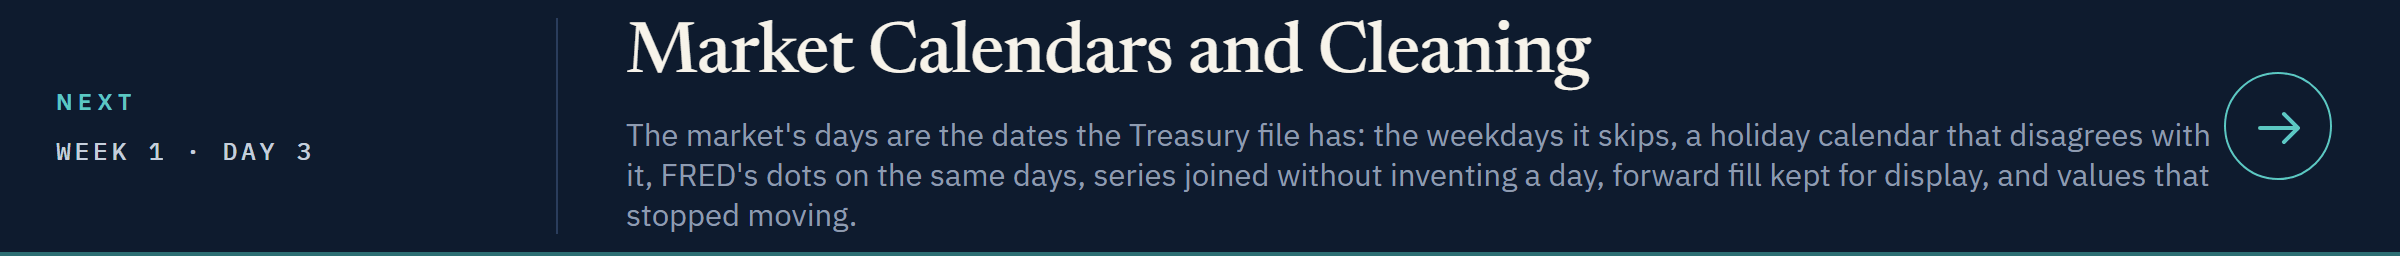](../day3/03_market_calendars_and_cleaning.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day3/03_market_calendars_and_cleaning.ipynb)